# Fraud detection in Credit Card transactions with LSTM model
In this demo, we will show Tensorflow functionality on IBM Z/LinuxONE using credit card transactional data in CSV format provided by IBM in kaggle.com. The data contains normal and also transactions that are likely fraudulent with patterns in historical data such as time since last transaction, amount of money transferred, location (city, country), type of card payment (online/offline), etc. The data is transformed and joined in a Pandas DataFrame, then split into training, validation and test datasets. A Long Short-Term Memory (LSTM) algorithm is then used to predict Fraud Yes/No in the transactions.

Gates are part of the hidden mechanics of the LSTM layer in Tensorflow/Keras. LSTM model in this demo will be built with 2 hidden LSTM layers. Each layer implicitly consists of the gates as depicted below.  

![LSTM CC Diagram](<./images/LSTM for CC on IBM Telum Chip.png>)

At first we will set up a machine learning environment by importing key libraries like TensorFlow (with Keras), NumPy, Pandas, and others for data processing, math operations, model saving/loading, and visualization. We also configures TensorFlow to suppress non-critical log messages and output the TensorFlow version.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import math
import joblib
print(tf.__version__)

2.18.1


In [2]:
timesteps = 7 # Six past transactions followed by current transaction

# Load dataset into Pandas DataFrame
In this section, we'll demonstrate how to load credit card transactions from a CSV file using the Pandas library, convert columns as needed, remove duplicates, and split the dataset into training (50%), validation (30%), and testing sets (20%). Then we generate the indices for each set using a random selection approach. The resulting indices can be used to access specific rows from the original dataframe or perform other operations.

In [3]:
tdf = pd.read_csv('transactions_history.csv')
tdf['Merchant Name'] = tdf['Merchant Name'].astype(str)
tdf.sort_values(by=['User','Card'], inplace=True)
tdf.reset_index(inplace=True, drop=True)
print (tdf.info())

# Get first of each User-Card combination
first = tdf[['User','Card']].drop_duplicates()
f = np.array(first.index)

# Drop the first N transactions
drop_list = np.concatenate([np.arange(x,x + timesteps - 1) for x in f])
index_list = np.setdiff1d(tdf.index.values,drop_list)

# Split into 0.5 train, 0.3 validate, 0.2 test
tot_length = index_list.shape[0]
train_length = tot_length // 2
validate_length = (tot_length - train_length) * 3 // 5
test_length = tot_length - train_length - validate_length
print (tot_length,train_length,validate_length, test_length)

# Generate list of indices for train, validate, test
np.random.seed(1111)
train_indices = np.random.choice(index_list, train_length, replace=False)
tv_list = np.setdiff1d(index_list, train_indices)
validate_indices = np.random.choice(tv_list, validate_length, replace=False)
test_indices = np.setdiff1d(tv_list, validate_indices)
print (train_indices, validate_indices, test_indices)

<class 'pandas.DataFrame'>
RangeIndex: 245864 entries, 0 to 245863
Data columns (total 15 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   User            245864 non-null  int64  
 1   Card            245864 non-null  int64  
 2   Year            245864 non-null  int64  
 3   Month           245864 non-null  int64  
 4   Day             245864 non-null  int64  
 5   Time            245864 non-null  str    
 6   Amount          245864 non-null  str    
 7   Use Chip        245864 non-null  str    
 8   Merchant Name   245864 non-null  str    
 9   Merchant City   245864 non-null  str    
 10  Merchant State  199705 non-null  str    
 11  Zip             197238 non-null  float64
 12  MCC             245864 non-null  int64  
 13  Errors?         4395 non-null    str    
 14  Is Fraud?       245864 non-null  str    
dtypes: float64(1), int64(6), str(8)
memory usage: 28.1 MB
None
245504 122752 73651 49101
[    50  68902 186069 ...  2

# Generate a test sample as original dataset + test indices
Indices are necessary to speed up large data processing. They play a crucial role in efficient data handling, especially when working with large datasets like millions of transaction records. Indexing enables quick access to rows and efficient joins/merges, optimizes memory usage and eliminates repeated sorting. 

In [4]:
def create_test_sample(df, indices):
    print(indices)
    rows = indices.shape[0]
    index_array = np.zeros((rows, timesteps), dtype=int)
    for i in range(timesteps):
        index_array[:,i] = indices + 1 - timesteps + i
    uniques = np.unique(index_array.flatten())
    df.loc[uniques].to_csv('test_220_40k.csv',index_label='Index')
    np.savetxt('test_220_40k.indices',indices.astype(int),fmt='%d')

create_test_sample(tdf, validate_indices[:40000]) # Uncomment this line to generate a test sample                    

[ 50001    960  75563 ...  24043 219530 174429]


# Define custom mapping functions
To customize how text columns are treated, we define custom mapping (encoder) functions using the astype and to_datetime methods in Pandas. These mapping functions can transform specific categories or values within a column to numerical representations of a specific type, allowing for more nuanced analysis and modeling. For example, a function amtEncoder that maps credit card transaction value in USD with $ to a float type value suitable for model training.

In [5]:
def timeEncoder(X):
    X_hm = X['Time'].str.split(':', expand=True)
    d = pd.to_datetime(dict(year=X['Year'],month=X['Month'],day=X['Day'],hour=X_hm[0],minute=X_hm[1])).astype('int64')
    return pd.DataFrame(d)

def amtEncoder(X):
    amt = X.apply(lambda x: x[1:]).astype(float).map(lambda amt: max(1,amt)).map(math.log)
    return pd.DataFrame(amt)

def decimalEncoder(X,length=5):
    dnew = pd.DataFrame()
    for i in range(length):
        dnew[i] = np.mod(X,10) 
        X = np.floor_divide(X,10)
    return dnew

def fraudEncoder(X):
    return np.where(X == 'Yes', 1, 0).astype(int)

# Fit pre-processing function using DataFrameMapper and pickle the mapper
In machine learning, pre-processing transforms raw data into a structured format by handling missing values, scaling features, encoding categorical variables, and addressing imbalanced data. It also involves tasks like feature engineering, outlier removal, and dimensionality reduction to enhance model performance and accuracy. These steps ensure the data is clean and ready for model training.

In [6]:
save_dir = 'shared/fraud_lstm'
os.makedirs(save_dir, exist_ok=True)

In [7]:
from sklearn_pandas import DataFrameMapper
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelBinarizer
from sklearn.impute import SimpleImputer

mapper = DataFrameMapper([('Is Fraud?', FunctionTransformer(fraudEncoder)),
                          (['Merchant State'], [SimpleImputer(strategy='constant'), FunctionTransformer(np.ravel),
                                               LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          (['Zip'], [SimpleImputer(strategy='constant'), FunctionTransformer(np.ravel),
                                     FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          ('Merchant Name', [LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          ('Merchant City', [LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          ('MCC', [LabelEncoder(), FunctionTransformer(decimalEncoder), OneHotEncoder()]),
                          (['Use Chip'], [SimpleImputer(strategy='constant'), LabelBinarizer()]),
                          (['Errors?'], [SimpleImputer(strategy='constant'), LabelBinarizer()]),
                          (['Year','Month','Day','Time'], [FunctionTransformer(timeEncoder), MinMaxScaler()]),
                          ('Amount', [FunctionTransformer(amtEncoder), MinMaxScaler()])
                         ], input_df=True, df_out=True)
mapper.fit(tdf)

,features,"[('Is Fraud?', ...), (['Merchant State'], ...), ...]"
,df_out,True
,input_df,True
,drop_cols,[]
,default,False
,sparse,False
Name,Type,Value
transformed_names_,list,[]


Serialize and deserialize fitted mapper as Python objects using pickle module. This allows you to save a preprocessing-function to a file and load it later without having to retrain it. 

In [8]:
joblib.dump(mapper, open(os.path.join(save_dir,'fitted_mapper.pkl'),'wb'))
mapper = joblib.load(open(os.path.join(save_dir,'fitted_mapper.pkl'),'rb'))

# Do a transform on one row to get number of mapped features (including label)

In [9]:
mapped_sample = mapper.transform(tdf[:100])
mapped_size = mapped_sample.shape[-1]
print(mapped_size)

190


# Utilities 

A set of helper functions and classes

In [10]:
from sklearn.metrics import f1_score

def f1(conf):
    precision = float(conf[1][1]) / (conf[1][1] + conf[0][1])
    recall    = float(conf[1][1]) / (conf[1][1] + conf[1][0])
    return 2 * precision * recall / (precision + recall)

# Custom metric that evaluates only the final timestep of each sequence.
# Pass the metric CLASS (not instance) so weights are created inside the model.
class LastStepMetric(tf.keras.metrics.Metric):
    def __init__(self, metric_class, name, **kwargs):
        super().__init__(name=name, **kwargs)
        self._m = metric_class(name=name)
    def update_state(self, y_true, y_pred, sample_weight=None):
        self._m.update_state(y_true[:, -1, :], y_pred[:, -1, :], sample_weight)
    def result(self):
        return self._m.result()
    def reset_state(self):
        self._m.reset_state()


# Defining and compiling the LSTM model with Tensorflow
LSTM (Long Short-Term Memory) needs to be defined first with a set of paramaters using integrated Keras in Tensorflow for simplicity. 
```input_shape=tf_input``` - is a matrix of ```timesteps=7``` the number of time steps per input sequence, and ```input_size``` is the number of features per time step.
Training and Testing is completed in batches of 16. 

Using visualization function within the Keras library - ```plot_model``` will create a graphical representation of the LSTM model's architecture.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (16, 7, 200)           │       312,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (16, 7, 200)           │       320,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (16, 7, 1)             │           201 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 633,001 (2.41 MB)

 Trainable params: 633,001 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

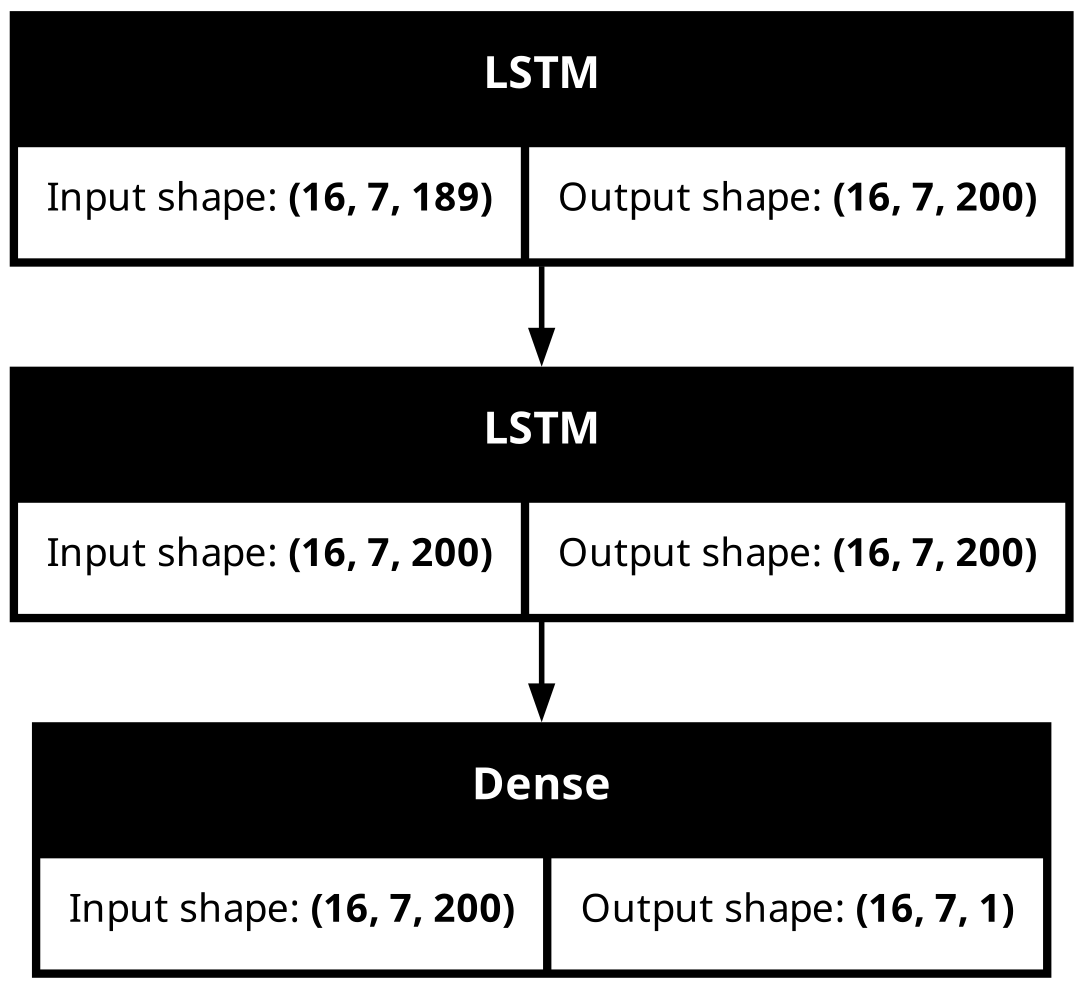

In [11]:
units = [200, 200]
input_size = mapped_size - 1
output_size = 1
batch_size = 16
timesteps = 7

lstm_model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(timesteps, input_size), batch_size=batch_size),
    tf.keras.layers.LSTM(units[0], return_sequences=True),
    tf.keras.layers.LSTM(units[1], return_sequences=True),
    tf.keras.layers.Dense(output_size, activation='sigmoid')
])

lstm_model.summary()
tf.keras.utils.plot_model(lstm_model, 'model.png', show_shapes=True)


In [12]:
# Compile model — metrics instantiated here so weights are created in the right context
metrics = [
    'accuracy',
    LastStepMetric(tf.keras.metrics.TruePositives,  name='TP'),
    LastStepMetric(tf.keras.metrics.FalsePositives, name='FP'),
    LastStepMetric(tf.keras.metrics.FalseNegatives, name='FN'),
    LastStepMetric(tf.keras.metrics.TrueNegatives,  name='TN'),
    tf.keras.metrics.TruePositives(name='tp'),
    tf.keras.metrics.FalsePositives(name='fp'),
    tf.keras.metrics.FalseNegatives(name='fn'),
    tf.keras.metrics.TrueNegatives(name='tn'),
]

lstm_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=metrics)


# Generator for training batches
Generator function produces one batch of data at a time using indices, instead of loading everything into memory at once. This allows streaming of large datasets for on-the-fly processing.

In [13]:
def gen_training_batch(df, mapper, index_list, batch_size):
    np.random.seed(98765)
    train_df = df.loc[index_list]
    non_fraud_indices = train_df[train_df['Is Fraud?'] == 'No'].index.values
    fraud_indices     = train_df[train_df['Is Fraud?'] == 'Yes'].index.values
    fsize = fraud_indices.shape[0]
    while True:
        indices = np.concatenate((fraud_indices,
                                  np.random.choice(non_fraud_indices, fsize, replace=False)))
        np.random.shuffle(indices)
        rows = indices.shape[0]
        index_array = np.zeros((rows, timesteps), dtype=int)
        for i in range(timesteps):
            index_array[:, i] = indices + 1 - timesteps + i
        full_df = mapper.transform(df.loc[index_array.flatten()])
        # shape: (rows, timesteps, features) — batch-major
        target_buffer = full_df['Is Fraud?'].to_numpy().reshape(rows, timesteps, 1)
        data_buffer   = full_df.drop(['Is Fraud?'], axis=1).to_numpy().reshape(rows, timesteps, -1)
        batch_ptr = 0
        while (batch_ptr + batch_size) <= rows:
            yield (data_buffer[batch_ptr:batch_ptr + batch_size],
                   target_buffer[batch_ptr:batch_ptr + batch_size])
            batch_ptr += batch_size


# Tensorflow training - LSTM model
Training the LSTM model via forward pass, loss calculation, backward pass, weights update, epoch loop and validation after each epoch. In ModelCheckpoint, after each epoch, Tensorflow checks the monitored metric  and if the monitored metric improves, the model is saved to the specified location. The best model is then retrieved from checkpoints and saved in the ```saved_dir```.

In [14]:
steps_per_epoch = 500
checkpoint_dir = "./checkpoints/ccf_220_keras_lstm_static/"
filepath = checkpoint_dir + "iter-{epoch:02d}/model.weights.h5"
batch_size = 16

print ("Learning...")
cp_callback = tf.keras.callbacks.ModelCheckpoint(filepath=filepath, save_weights_only=True, verbose=1)
train_generate = gen_training_batch(tdf,mapper,train_indices,batch_size)
lstm_model.fit(train_generate, epochs=5, steps_per_epoch=steps_per_epoch, verbose=1, callbacks=[cp_callback])

lstm_model.save_weights(os.path.join(save_dir,"model.weights.h5"))
lstm_model.export(save_dir)

Learning...
Epoch 1/5
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - FN: 207.0080 - FP: 83.1486 - TN: 1925.1064 - TP: 1776.7369 - accuracy: 0.9230 - fn: 1003.1064 - fp: 428.8976 - loss: 0.2040 - tn: 19640.0020 - tp: 6871.9940
Epoch 1: saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-01/model.weights.h5

Epoch 1: finished saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-01/model.weights.h5
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - FN: 241.0000 - FP: 107.0000 - TN: 3910.0000 - TP: 3742.0000 - accuracy: 0.9689 - fn: 1154.0000 - fp: 588.0000 - loss: 0.0854 - tn: 39602.0000 - tp: 14656.0000
Epoch 2/5
498/500 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - FN: 5.3213 - FP: 6.0763 - TN: 1978.2028 - TP: 2002.3996 - accuracy: 0.9972 - fn: 17.4598 - fp: 63.6486 - loss: 0.0114 - tn: 19908.5582 - tp: 7954.3333
Epoch 2: saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-02/model.weights.h5

Epoch 2: finished saving model to ./checkpoints/ccf_220_keras_lstm_static/iter-02/model

INFO:tensorflow:Assets written to: shared/fraud_lstm/assets


Saved artifact at 'shared/fraud_lstm'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 7, 189), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 7, 1), dtype=tf.float32, name=None)
Captures:
  4394198745744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394272264016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394198748624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394198748048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394198748240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394198749584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394198746512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  4394198749392: TensorSpec(shape=(), dtype=tf.resource, name=None)


# Generator for validation/test batches
In similar to the generator used in training process, we will use the generator function for test batches during the testing step.

In [15]:
def gen_test_batch(df, mapper, indices, batch_size):
    rows = indices.shape[0]
    index_array = np.zeros((rows, timesteps), dtype=int)
    for i in range(timesteps):
        index_array[:, i] = indices + 1 - timesteps + i
    count = 0
    while count + batch_size <= rows:
        full_df = mapper.transform(df.loc[index_array[count:count + batch_size].flatten()])
        # shape: (batch_size, timesteps, features) — batch-major
        data    = full_df.drop(['Is Fraud?'], axis=1).to_numpy().reshape(batch_size, timesteps, -1)
        targets = full_df['Is Fraud?'].to_numpy().reshape(batch_size, timesteps, 1)
        count += batch_size
        yield data, targets


# Tensorflow testing - LSTM model
During the model testing step in TensorFlow/Keras, we will evaluate the trained LSTM model on unseen data (a test set) to measure its final performance.The model is loaded from the ```saved_model``` location, compiled and then tested via ```evaluate``` function.
We will use small and bigger batches for a Quick test and Full test accordingly.

In [16]:
batch_size = 2000
input_size = mapped_size - 1
output_size = 1
units = [200, 200]
timesteps = 7

new_model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(timesteps, input_size), batch_size=batch_size),
    tf.keras.layers.LSTM(units[0], return_sequences=True),
    tf.keras.layers.LSTM(units[1], return_sequences=True),
    tf.keras.layers.Dense(output_size, activation='sigmoid')
])
new_model.load_weights(os.path.join(save_dir, 'model.weights.h5'))
new_model.compile(
    optimizer='adam', loss='binary_crossentropy',
    metrics=[
        'accuracy',
        LastStepMetric(tf.keras.metrics.TruePositives,  name='TP'),
        LastStepMetric(tf.keras.metrics.FalsePositives, name='FP'),
        LastStepMetric(tf.keras.metrics.FalseNegatives, name='FN'),
        LastStepMetric(tf.keras.metrics.TrueNegatives,  name='TN'),
        tf.keras.metrics.TruePositives(name='tp'),
        tf.keras.metrics.FalsePositives(name='fp'),
        tf.keras.metrics.FalseNegatives(name='fn'),
        tf.keras.metrics.TrueNegatives(name='tn'),
    ]
)

ddf = pd.read_csv('test_220_40k.csv', dtype={'Merchant Name': 'str'}, index_col='Index')
indices = np.loadtxt('test_220_40k.indices')

print('\nQuick test')
test_generate = gen_test_batch(ddf, mapper, indices, batch_size)
new_model.evaluate(test_generate, verbose=1)

print('\nFull test')
test_generate = gen_test_batch(tdf, mapper, test_indices, batch_size)
new_model.evaluate(test_generate, verbose=1)



Quick test
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 174ms/step - FN: 8.0000 - FP: 28.0000 - TN: 39925.0000 - TP: 39.0000 - accuracy: 0.9982 - fn: 53.0000 - fp: 455.0000 - loss: 0.0061 - tn: 279242.0000 - tp: 250.0000

Full test


/opt/venv/lib64/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


24/24 ━━━━━━━━━━━━━━━━━━━━ 5s 203ms/step - FN: 8.0000 - FP: 24.0000 - TN: 47930.0000 - TP: 38.0000 - accuracy: 0.9984 - fn: 56.0000 - fp: 492.0000 - loss: 0.0056 - tn: 335164.0000 - tp: 288.0000


/opt/venv/lib64/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


[0.005594303831458092,
 0.998369038105011,
 38.0,
 24.0,
 8.0,
 47930.0,
 288.0,
 492.0,
 56.0,
 335164.0]

## Convert to ONNX
tf2onnx is a tool that converts TensorFlow models into ONNX (Open Neural Network Exchange) format, making them compatible with other platforms and backends. ONNX is an open-source format designed for interoperability across different deep learning frameworks, allowing models trained in TensorFlow (or other frameworks like PyTorch) to be used on different platforms without needing to be re-trained or re-implemented. In our context here, models trained on x86 can be exported to ONNX and deployed on IBM Z/LinuxONE for inferencing. 

![LSTM CC Diagram](<./images/Train Anywhere Inference on IBM Z.png>)

In [17]:
import tensorflow as tf
from tensorflow import keras
import tf2onnx
import onnx

input_signature = [tf.TensorSpec([None, timesteps, input_size], tf.float32, name='input')]
@tf.function(input_signature=input_signature)
def model_fn(x):
    return new_model(x)

onnx_model, _ = tf2onnx.convert.from_function(model_fn, input_signature=input_signature, opset=13)
onnx.save_model(onnx_model, 'fraud_lstm.onnx')
print('Saved fraud_lstm.onnx')


I0000 00:00:1792273708.712369      24 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792273708.712523      24 single_machine.cc:361] Starting new session
I0000 00:00:1792273708.987271      24 devices.cc:76] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 0 (Note: TensorFlow was not compiled with CUDA or ROCm support)
I0000 00:00:1792273708.987399      24 single_machine.cc:361] Starting new session
I0000 00:00:1792273709.147295      24 mlir_graph_optimization_pass.cc:401] MLIR V1 optimization pass is not enabled


Saved fraud_lstm.onnx


## IBM zDNN / NNPA Hardware Acceleration
IBM LinuxONE z17 includes the **Neural Network Processing Assist (NNPA)** facility — dedicated on-chip AI acceleration silicon.
The `ibm-zdnn-plugin` registers optimised kernels that replace the standard CPU path for **LSTM cells**, `MatMul`, `Sigmoid`, and related ops.
This is particularly impactful for LSTM workloads: the entire fused LSTM cell computation (input gate, forget gate, cell update, output gate) is dispatched to NNPA hardware.
The cells below verify the plugin is active and benchmark batch inference throughput.

In [18]:
import importlib.metadata, time, glob, os
import numpy as np

# ── 1. Confirm ibm-zdnn-plugin is installed and the kernel .so is loaded ──
zdnn_version = importlib.metadata.version('ibm-zdnn-plugin')
print(f'ibm-zdnn-plugin version : {zdnn_version}')

so_path = glob.glob(
    '/opt/venv/lib*/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so'
)
if so_path:
    size_mb = os.path.getsize(so_path[0]) / 1024**2
    print(f'zDNN kernel library     : {so_path[0]}  ({size_mb:.1f} MB loaded)')
else:
    print('WARNING: _z_ops.so not found — NNPA acceleration inactive')

print(f'TensorFlow device       : {tf.config.list_physical_devices()}')
print()
print('Ops accelerated by NNPA on z17 for this LSTM model:')
for op in ['LSTM fused cell (all 4 gates)', 'MatMul (Dense output layer)',
           'Sigmoid activation', 'BatchMatMul']:
    print(f'  ✔  {op}')


ibm-zdnn-plugin version : 2.3.0
zDNN kernel library     : /opt/venv/lib/python3.12/site-packages/tensorflow/core/kernels/_z_ops.so  (17.5 MB loaded)
TensorFlow device       : [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]

Ops accelerated by NNPA on z17 for this LSTM model:
  ✔  LSTM fused cell (all 4 gates)
  ✔  MatMul (Dense output layer)
  ✔  Sigmoid activation
  ✔  BatchMatMul


In [19]:
# ── 2. Build a benchmark batch from the test dataset ─────────────────────
# Use the same batch_size=2000 model loaded in the test section above
BENCH_BATCH = 2000
REPEATS     = 10

# Build one batch of sequences for benchmarking
bench_indices = test_indices[:BENCH_BATCH]
index_array   = np.zeros((BENCH_BATCH, timesteps), dtype=int)
for i in range(timesteps):
    index_array[:, i] = bench_indices + 1 - timesteps + i
bench_df   = mapper.transform(tdf.loc[index_array.flatten()])
bench_data = bench_df.drop(['Is Fraud?'], axis=1).to_numpy().reshape(BENCH_BATCH, timesteps, -1).astype('float32')
bench_data = tf.constant(bench_data)

# Warm up
_ = new_model(bench_data, training=False)

times = []
for _ in range(REPEATS):
    t0 = time.perf_counter()
    preds = new_model(bench_data, training=False)
    _ = preds.numpy()
    times.append(time.perf_counter() - t0)

times      = sorted(times)
median_ms  = times[len(times)//2] * 1000
best_ms    = times[0]             * 1000
throughput = BENCH_BATCH / (median_ms / 1000)

print(f'Batch size              : {BENCH_BATCH} sequences  ({timesteps} timesteps each)')
print(f'Median inference time   : {median_ms:.2f} ms')
print(f'Best  inference time    : {best_ms:.2f} ms')
print(f'Throughput              : {throughput:,.0f} sequences / second')
print()
print('Note: Both LSTM layers and the Dense output layer are dispatched')
print('      to the NNPA facility via ibm-zdnn-plugin (_z_ops.so).')


Batch size              : 2000 sequences  (7 timesteps each)
Median inference time   : 289.33 ms
Best  inference time    : 271.72 ms
Throughput              : 6,912 sequences / second

Note: Both LSTM layers and the Dense output layer are dispatched
      to the NNPA facility via ibm-zdnn-plugin (_z_ops.so).


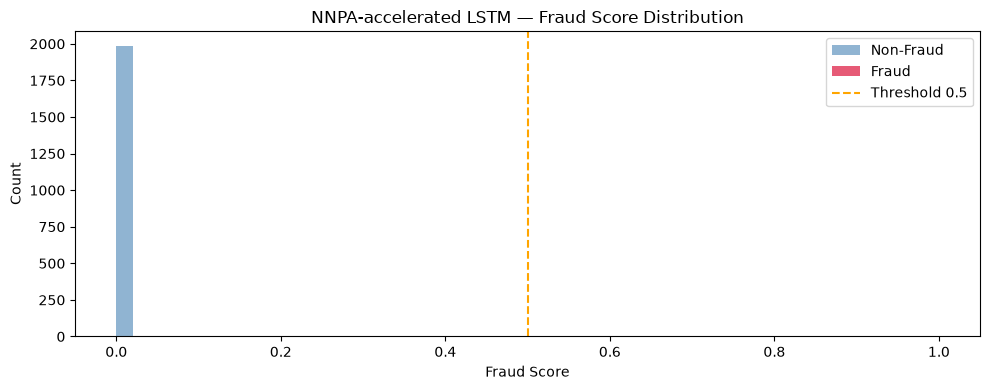

TP=3  FP=6  FN=0  TN=1991
Precision: 0.3333   Recall: 1.0000


In [20]:
# ── 3. Show fraud detection score distribution ────────────────────────────
import matplotlib.pyplot as plt

scores      = preds.numpy()[:, -1, 0]   # last timestep, single output
pred_labels = (scores >= 0.5).astype(int)

# Get true labels for the same rows
true_labels = bench_df['Is Fraud?'].to_numpy().reshape(BENCH_BATCH, timesteps)[:, -1]

fraud_scores    = scores[true_labels == 1]
non_fraud_scores = scores[true_labels == 0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(non_fraud_scores, bins=50, alpha=0.6, color='steelblue', label='Non-Fraud')
ax.hist(fraud_scores,     bins=50, alpha=0.7, color='crimson',   label='Fraud')
ax.axvline(0.5, color='orange', linestyle='--', linewidth=1.5, label='Threshold 0.5')
ax.set_xlabel('Fraud Score')
ax.set_ylabel('Count')
ax.set_title('NNPA-accelerated LSTM — Fraud Score Distribution')
ax.legend()
plt.tight_layout()
plt.show()

tp = int(((pred_labels == 1) & (true_labels == 1)).sum())
fp = int(((pred_labels == 1) & (true_labels == 0)).sum())
fn = int(((pred_labels == 0) & (true_labels == 1)).sum())
tn = int(((pred_labels == 0) & (true_labels == 0)).sum())
precision = tp / (tp + fp) if (tp + fp) > 0 else 0
recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
print(f'TP={tp}  FP={fp}  FN={fn}  TN={tn}')
print(f'Precision: {precision:.4f}   Recall: {recall:.4f}')
